# Linear momentum in a periodic box (a report)

A periodic 3-D Cartesian box (8^3) with a radiation wave along the xyz diagonal, amplitude 1e-3,
8 cycles. Total linear momentum $P$ = gas (`hydro_u`) + radiation (face momenta $F_f/c^2$ of
`vet_face`). `dP_cyc` = largest component of $|P - P_0|$ / $\sum|p_\mathrm{gas}|$ per cycle.

**This is a report, not a criterion.** The scheme does not conserve linear momentum in general
(the face-flux cone cut, the well-balancing residual and the floor velocity rules change it and
are not booked; see `tests/vet_clean/README.md`). Where none of them acts, as in this linear box,
dP is round-off. The test passes when the run completes, dP is finite and there is no
`CLEAN WARNING`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TEST = 'momentum_box'
res = nb.suite(TEST, EXE, WORK, THREADS)

loading the existing run runs/momentum_box


cycle   time      (P - P0)_x / sum|p_gas|   _y          _z
  0  0.00000   +0.00e+00   +0.00e+00   +0.00e+00
  1  0.04909   +4.49e-17   +5.62e-17   +5.73e-17
  2  0.09818   +4.54e-17   +5.73e-17   +5.87e-17
  3  0.14726   +4.77e-17   +5.75e-17   +5.67e-17
  4  0.19635   +5.06e-17   +5.53e-17   +5.87e-17
  5  0.24544   +4.81e-17   +5.16e-17   +5.43e-17
  6  0.29453   +4.86e-17   +5.27e-17   +5.47e-17
  7  0.34361   +4.78e-17   +5.07e-17   +5.28e-17
  8  0.39270   +4.92e-17   +5.14e-17   +5.49e-17


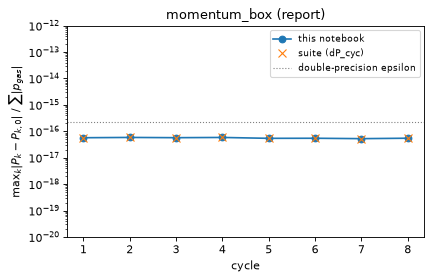

dP_max = 5.87e-17, CLEAN WARNING lines: 0
PASS momentum_box   criterion {"equal": {"warnings": 0}}


In [3]:
# per-cycle total momentum from the dumps (the definition of run_tests.t_momentum_box)
vett = nb.vett
d = os.path.join(WORK, TEST, 'run')
p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
cl, n = float(p['rad_vet']['c_light']), int(p['mesh']['nx1'])
dv, P, s0 = 1.0/n**3, {}, None          # unit box, n^3 cells
for fa, fh in zip(vett.bins(d, 'vet_face'), vett.bins(d, 'hydro_u')):
    A, H = vett.read_bin(fa), vett.read_bin(fh)
    pr = np.array([A['vet_fx%d' % k].sum() for k in (1, 2, 3)])*dv/cl**2   # radiation: face momenta F_f / c^2
    pg = np.array([H['mom%d' % k].sum() for k in (1, 2, 3)])*dv          # gas
    if s0 is None:
        s0 = sum(np.abs(H['mom%d' % k]).sum() for k in (1, 2, 3))*dv
    P[A['cycle']] = (A['time'], pg + pr)
cyc = sorted(P); P0 = P[cyc[0]][1]
print('cycle   time      (P - P0)_x / sum|p_gas|   _y          _z')
for k in cyc:
    print('%3d  %.5f   %+.2e   %+.2e   %+.2e' % ((k, P[k][0]) + tuple((P[k][1] - P0)/s0)))
dp = np.array([np.abs(P[k][1] - P0).max()/s0 for k in cyc[1:]])
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.semilogy(cyc[1:], np.maximum(dp, 1e-20), 'o-', label='this notebook')
ax.semilogy(np.arange(1, len(res['dP_cyc']) + 1), res['dP_cyc'], 'x', ms=8, label='suite (dP_cyc)')
ax.axhline(np.finfo(float).eps, c='0.5', ls=':', lw=1, label='double-precision epsilon')
ax.set(xlabel='cycle', ylabel=r'max$_k |P_k - P_{k,0}|$ / $\sum|p_{gas}|$', ylim=(1e-20, 1e-12),
       title='momentum_box (report)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('dP_max = %.3g, CLEAN WARNING lines: %d' % (res['dP_max'], res['warnings']))
_ = nb.verdict(TEST, res)